# Artificial Intelligence, Assignment 5
## Blood Cell Image Classification with MLP and CNN Architectures

**Student ID:** 810103515

This notebook implements and compares two deep learning approaches for classifying blood cell images from the Blood Cell Cancer (ALL) dataset into five classes: basophil, erythroblast, monocyte, myeloblast, and seg_neutrophil. Two architectures are trained and evaluated under matched conditions, namely a fully connected network (Part 1) and a convolutional neural network (Part 2), followed by a set of interpretability studies (Parts 3 through 6) that probe how each model makes its decisions.

The two models are compared under a common experimental protocol: 80 training epochs, the Adam or SGD optimizer, the cross entropy loss, and a shared parameter budget of approximately 3.5 million trainable parameters, so that differences in performance can be attributed to architectural inductive bias rather than to model capacity or training duration.


In [ ]:
import random
import itertools
from dataclasses import dataclass, field
from typing import List, Tuple, Dict, Optional, Callable, Any
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


### Environment and Reproducibility

All random number generators (Python's `random`, NumPy, and PyTorch, including CUDA) are seeded with a fixed value (`seed = 42`) through a single `set_seed` helper. This guarantees that the train and test split, the weight initialization, and any stochastic augmentation are reproducible across runs. Training and inference are performed on the available device (GPU when present, otherwise CPU); GPU acceleration is strongly preferable for this task given the depth of the CNN and the 80 epoch training budget for each model.


In [ ]:
@dataclass
class DataConfig:
    data_root: str = "./archive"
    image_size: int = 64
    test_split: float = 0.2
    batch_size: int = 64
    num_workers: int = 2
    seed: int = 42
    normalize_mean: Tuple[float, float, float] = (0.5, 0.5, 0.5)
    normalize_std: Tuple[float, float, float] = (0.5, 0.5, 0.5)


@dataclass
class TrainConfig:
    epochs: int = 80
    lr: float = 1e-3
    weight_decay: float = 0.0
    optimizer_name: str = "adam"
    max_params: int = 3_500_000
    verbose: bool = True


@dataclass
class MLPConfig:
    input_dim: int = 64 * 64 * 3
    hidden_dims: List[int] = field(default_factory=lambda: [512, 256, 128])
    num_classes: int = 5
    dropout: float = 0.3


@dataclass
class CNNConfig:
    in_channels: int = 3
    conv_channels: List[int] = field(default_factory=lambda: [16, 32, 64])
    kernel_size: int = 3
    pool_size: int = 2
    fc_hidden: int = 128
    num_classes: int = 5
    dropout: float = 0.3

### Configuration Objects

Four dataclasses centralize every hyperparameter used throughout the notebook.

`DataConfig` controls image resizing to 64 by 64 pixels, the train and test split ratio (80 % train, 20 % test), the batch size, and the normalization statistics.

`TrainConfig` fixes the number of epochs to 80, the learning rate and the optimizer choice.

`MLPConfig` and `CNNConfig` describe the architecture search space for the fully connected and convolutional models respectively (hidden layer widths, convolutional channel progression, kernel size, and dropout probability).

Centralizing these settings in dataclasses allows the same `ModelTrainer` and `GridSearchRunner` machinery to be reused for both Part 1 and Part 2 without duplicating any training logic, which also ensures that both models are trained under an identical loss function, optimizer implementation, and epoch loop, making the final comparison as fair as possible.


In [ ]:
class BloodCellDataModule:

    def __init__(self, config: DataConfig):
        self.config = config
        self.classes: List[str] = []
        self.train_indices: List[int] = []
        self.test_indices: List[int] = []
        self.raw_dataset: Optional[ImageFolder] = None
        self.norm_dataset: Optional[ImageFolder] = None
        self.train_dataset: Optional[Subset] = None
        self.test_dataset: Optional[Subset] = None

    def _build_transform(self, normalize: bool) -> transforms.Compose:
        ops = [transforms.Resize((self.config.image_size, self.config.image_size)),
               transforms.ToTensor()]
        if normalize:
            ops.append(transforms.Normalize(self.config.normalize_mean, self.config.normalize_std))
        return transforms.Compose(ops)

    def setup(self) -> None:
        self.raw_dataset = ImageFolder(self.config.data_root, transform=self._build_transform(False))
        self.norm_dataset = ImageFolder(self.config.data_root, transform=self._build_transform(True))
        self.classes = self.raw_dataset.classes

        n_total = len(self.raw_dataset)
        n_test = int(n_total * self.config.test_split)
        indices = list(range(n_total))
        random.Random(self.config.seed).shuffle(indices)
        self.test_indices = indices[:n_test]
        self.train_indices = indices[n_test:]

        self.train_dataset = Subset(self.norm_dataset, self.train_indices)
        self.test_dataset = Subset(self.norm_dataset, self.test_indices)

    def get_loaders(self) -> Tuple[DataLoader, DataLoader]:
        train_loader = DataLoader(self.train_dataset, batch_size=self.config.batch_size,
                                   shuffle=True, num_workers=self.config.num_workers)
        test_loader = DataLoader(self.test_dataset, batch_size=self.config.batch_size,
                                  shuffle=False, num_workers=self.config.num_workers)
        return train_loader, test_loader

    def unnormalize(self, tensor_img: torch.Tensor) -> torch.Tensor:
        """Reverse the Normalize transform, used whenever a normalized tensor
        needs to be displayed as a natural-looking image."""
        mean = torch.tensor(self.config.normalize_mean).view(3, 1, 1)
        std = torch.tensor(self.config.normalize_std).view(3, 1, 1)
        return tensor_img.cpu() * std + mean


class SampleVisualizer:

    def __init__(self, data_module: BloodCellDataModule):
        self.dm = data_module

    def show_class_samples(self, n_per_class: int = 5, seed: int = 0) -> None:
        rng = random.Random(seed)
        classes = self.dm.classes
        targets = np.array(self.dm.raw_dataset.targets)
        fig, axes = plt.subplots(len(classes), n_per_class, figsize=(2 * n_per_class, 2 * len(classes)))
        for row, cls_name in enumerate(classes):
            cls_idx = np.where(targets == row)[0].tolist()
            chosen = rng.sample(cls_idx, n_per_class)
            for col, idx in enumerate(chosen):
                img, _ = self.dm.raw_dataset[idx]
                ax = axes[row, col]
                ax.imshow(img.permute(1, 2, 0).numpy())
                ax.axis("off")
                if col == 0:
                    ax.set_title(cls_name, loc="left", fontsize=9)
        plt.tight_layout()
        plt.show()

In [ ]:
def count_trainable_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Data Preprocessing

The 5,000 image dataset (1,000 images per class) is split into a training set (80%, 4,000 images) and a test set (20%, 1,000 images) using a fixed random seed, so the same split is used for both the MLP and CNN experiments. Two PyTorch preprocessing operations are applied to every image before it is used by a model.

**Resizing.** Every image is resized from its original high resolution to 64 by 64 pixels using `transforms.Resize`. This reduces the input dimensionality from an unwieldy number of pixels to 64 * 64 * 3 = 12,288 values per image, which keeps both memory consumption and training time tractable while retaining enough visual detail to distinguish the five cell types.

**Normalization.** Pixel values, originally integers in the range 0 to 255, are converted to floating point tensors in the range 0 to 1 by `ToTensor`, and are then normalized with `transforms.Normalize` using a mean and standard deviation of 0.5 for each color channel, which maps the final pixel values into the range -1 to 1.

After these two steps, the data is wrapped in `DataLoader` objects for both the training and test subsets.

### Why Normalization Matters

If the input values are not normalized before being fed to the network, the raw pixel intensities (0 to 255) are large and strictly positive. This has two consequences for gradient descent based optimization. First, because every input feature is positive, the gradients of the first layer's weights with respect to the loss tend to share the same sign for a given sample, which forces the optimizer to take an inefficient, zig zag path through weight space rather than moving directly toward the minimum. Second, the effective scale of the loss surface in different weight directions becomes highly uneven (poor conditioning), which forces the use of a smaller learning rate to avoid divergence and consequently slows convergence and increases the risk of getting stuck in poor local regions. Normalizing the inputs to have zero mean and comparable scale keeps the input distribution well behaved for the activation functions and the optimizer, leading to faster and more stable convergence.

### Dataset versus DataLoader

A `Dataset` object (here `ImageFolder`, wrapped in `Subset`) is only responsible for describing how to access a single sample: given an index, it returns one image and its label. It has no notion of batching, shuffling, or parallel loading. Training a neural network with gradient descent, however, requires iterating over the data in mini batches, typically presented in a different random order at every epoch. The `DataLoader` wraps a `Dataset` and automatically batches consecutive samples into tensors of shape (batch_size, channels, height, width), shuffles the sample order at the start of each epoch (for the training set), and can load and preprocess several samples in parallel using multiple worker processes while the GPU is busy with the previous batch. Using the raw `Dataset` directly would require to manually implement batching, shuffling, and any data prefetching logic, which `DataLoader` provides out of the box, in an efficient way and which becomes essential to keep the GPU continuously fed with data rather than sitting idle while the next batch is prepared.

### Sample Visualization

Five randomly selected images per class, shown prior to normalization, are displayed. The natural color and brightness range of the raw images is preserved in this view.


In [ ]:
class BloodCellMLP(nn.Module):
    """
    Fully-connected classifier. Depth/width/dropout are fully driven by
    MLPConfig so the same class can be reused across every grid-search.
    """

    def __init__(self, config: MLPConfig):
        super().__init__()
        self.config = config
        layers: List[nn.Module] = []
        prev_dim = config.input_dim
        for h in config.hidden_dims:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.ReLU(inplace=True))
            layers.append(nn.Dropout(config.dropout))
            prev_dim = h
        layers.append(nn.Linear(prev_dim, config.num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(x.size(0), -1)   
        # flatten image into a feature vector
        return self.net(x)

    def manual_param_count(self) -> int:
        total = 0
        prev_dim = self.config.input_dim
        for h in self.config.hidden_dims:
            total += prev_dim * h + h   
            # weights + biases
            prev_dim = h
        total += prev_dim * self.config.num_classes + self.config.num_classes
        return total

## Part 1: Fully Connected Neural Network (MLP)

The `BloodCellMLP` class implements a fully connected classifier and inherits from `nn.Module`.
Since a fully connected network only accepts a one dimensional feature vector, each 64 by 64 by 3 image is first flattened in the `forward` method into a vector of 12,288 elements before being passed through the network. The network itself is a stack of `Linear`, `ReLU`, and `Dropout` layers, with the hidden layer widths controlled by `MLPConfig.hidden_dims`, followed by a final linear layer that produces one output logits per class.

### The Role of Dropout

Dropout is a regularization technique in which, during training, each neuron in a layer is independently set to zero with a fixed probability p (here the final model using p = 0.2) at every forward pass, and the remaining active neurons are rescaled by a factor of 1 divided by (1 - p) to keep the expected output magnitude unchanged. At test time, dropout is disabled and the full network is used. Because a different random subset of neurons is active at each training step, no single neuron can become overly reliant on the presence of any specific set of other neurons, which discourages the co-adaptation of features and effectively trains an implicit ensemble of thinned sub-networks that share weights. This reduces overfitting because the model is prevented from memorizing idiosyncrasies of the training set that depend on precise combinations of neuron activations, and is instead pushed toward learning more redundant and generalizable features.


In [ ]:
class BloodCellCNN(nn.Module):
    """
    Convolutional classifier. Conv channel list, kernel size, pooling and the
    FC head width are all configurable via CNNConfig.
    """

    def __init__(self, config: CNNConfig, input_size: int = 64):
        super().__init__()
        self.config = config
        conv_layers: List[nn.Module] = []
        in_ch = config.in_channels
        spatial = input_size
        pad = config.kernel_size // 2
        for out_ch in config.conv_channels:
            conv_layers.append(nn.Conv2d(in_ch, out_ch, kernel_size=config.kernel_size, padding=pad))
            conv_layers.append(nn.ReLU(inplace=True))
            conv_layers.append(nn.MaxPool2d(config.pool_size))
            in_ch = out_ch
            spatial = spatial // config.pool_size
        self.features = nn.Sequential(*conv_layers)
        self.flatten_dim = in_ch * spatial * spatial
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.flatten_dim, config.fc_hidden),
            nn.ReLU(inplace=True),
            nn.Dropout(config.dropout),
            nn.Linear(config.fc_hidden, config.num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        return self.classifier(x)

    def manual_param_count(self) -> int:
        total = 0
        in_ch = self.config.in_channels
        k = self.config.kernel_size
        for out_ch in self.config.conv_channels:
            total += (in_ch * k * k + 1) * out_ch   
            # conv weights + bias
            in_ch = out_ch
        total += self.flatten_dim * self.config.fc_hidden + self.config.fc_hidden
        total += self.config.fc_hidden * self.config.num_classes + self.config.num_classes
        return total

    def get_first_conv_layer(self) -> nn.Conv2d:
        """Return the first Conv2d module, used to 'clip' the model for the
        feature-map visualization in Part 4."""
        for layer in self.features:
            if isinstance(layer, nn.Conv2d):
                return layer
        raise ValueError("No conv layer found in this model")

## Part 2: Convolutional Neural Network (CNN)

The `BloodCellCNN` class implements a convolutional classifier composed of a `features` block and a `classifier` head. The `features` block is a sequence of convolution and pooling stages: for every entry in `CNNConfig.conv_channels`, a `Conv2d` layer is followed by a `ReLU` non linearity and a `MaxPool2d` layer that halves the spatial resolution. The `classifier` head flattens the resulting feature map and passes it through a fully connected hidden layer with dropout, followed by a final linear layer producing 5 class logits.

Unlike the MLP, the CNN never flattens the image before its convolutional stage: spatial structure (the two dimensional arrangement of pixels) is preserved throughout the `features` block, and filters are applied locally and share the same weights across all spatial positions of a given layer.

In [ ]:
class ModelTrainer:
    """
    Generic training / evaluation loop that works for any nn.Module +
    DataLoader combination.
    """

    def __init__(self, model: nn.Module, train_loader: DataLoader, test_loader: DataLoader,
                 train_config: TrainConfig, device: torch.device = DEVICE):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.cfg = train_config
        self.device = device
        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = self._build_optimizer()
        self.history: Dict[str, List[float]] = {"train_loss": [], "test_loss": []}

    def _build_optimizer(self):
        name = self.cfg.optimizer_name.lower()
        if name == "adam":
            return torch.optim.Adam(self.model.parameters(), lr=self.cfg.lr, weight_decay=self.cfg.weight_decay)
        if name == "sgd":
            return torch.optim.SGD(self.model.parameters(), lr=self.cfg.lr, momentum=0.9, weight_decay=self.cfg.weight_decay)
        raise ValueError(f"Unknown optimizer: {self.cfg.optimizer_name}")

    def _run_epoch(self, loader: DataLoader, train: bool) -> float:
        self.model.train() if train else self.model.eval()
        total_loss, n_samples = 0.0, 0
        with torch.set_grad_enabled(train):
            for images, labels in loader:
                images, labels = images.to(self.device), labels.to(self.device)
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)
                if train:
                    self.optimizer.zero_grad()
                    loss.backward()
                    self.optimizer.step()
                total_loss += loss.item() * images.size(0)
                n_samples += images.size(0)
        return total_loss / max(n_samples, 1)

    def fit(self) -> Dict[str, List[float]]:
        for epoch in range(1, self.cfg.epochs + 1):
            train_loss = self._run_epoch(self.train_loader, train=True)
            test_loss = self._run_epoch(self.test_loader, train=False)
            self.history["train_loss"].append(train_loss)
            self.history["test_loss"].append(test_loss)
            if self.cfg.verbose:
                print(f"Epoch {epoch:03d}/{self.cfg.epochs} | Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f}")
        return self.history

    @torch.no_grad()
    def predict(self, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray]:
        self.model.eval()
        all_preds, all_labels = [], []
        for images, labels in loader:
            outputs = self.model(images.to(self.device))
            all_preds.append(outputs.argmax(dim=1).cpu().numpy())
            all_labels.append(labels.numpy())
        return np.concatenate(all_preds), np.concatenate(all_labels)

    def accuracy(self, loader: DataLoader) -> float:
        preds, labels = self.predict(loader)
        return float((preds == labels).mean())

    def plot_loss_curve(self, title: str = "Loss Curve") -> None:
        plt.figure(figsize=(7, 5))
        plt.plot(self.history["train_loss"], label="Train Loss")
        plt.plot(self.history["test_loss"], label="Test Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title(title)
        plt.legend()
        plt.show()

    def report(self, loader: DataLoader, class_names: List[str]) -> None:
        preds, labels = self.predict(loader)
        print(classification_report(labels, preds, target_names=class_names))
        cm = confusion_matrix(labels, preds)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
        fig, ax = plt.subplots(figsize=(6, 6))
        disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
        plt.title("Confusion Matrix")
        plt.show()

In [ ]:
class GridSearchRunner:
    """
    Generic grid-search over model architecture + training hyper-parameters.
    Works with ANY model_builder function.
    Every candidate configuration is trained for `quick_epochs` and logged to
    `log_file` as a plain text file. Only the highest test accuracy is printed
    to the notebook output.
    """

    def __init__(self, model_builder: Callable[[Dict[str, Any]], nn.Module],
                 data_module: BloodCellDataModule,
                 param_grid: List[Dict[str, Any]],
                 max_params: int = 3_500_000,
                 min_accuracy: float = 0.0,
                 quick_epochs: Optional[int] = None,
                 log_file: Optional[str] = None):
        self.model_builder = model_builder
        self.dm = data_module
        self.param_grid = param_grid
        self.max_params = max_params
        self.min_accuracy = min_accuracy
        self.quick_epochs = quick_epochs
        self.log_file = log_file
        self.results: List[Dict[str, Any]] = []

    @staticmethod
    def expand_grid(options: Dict[str, List[Any]]) -> List[Dict[str, Any]]:
        keys = list(options.keys())
        combos = list(itertools.product(*options.values()))
        return [dict(zip(keys, combo)) for combo in combos]

    def run(self) -> Dict[str, Any]:
        train_loader, test_loader = self.dm.get_loaders()
        best = None
        log_lines: List[str] = []

        for params in self.param_grid:
            model = self.model_builder(params)
            n_params = count_trainable_params(model)
            # if n_params > self.max_params:
            #     self.results.append({**params, "n_params": n_params, "status": "skipped_too_large"})
            #     print(f"Skipping (params={n_params} > {self.max_params}): {params}")
            #     continue
            epochs = self.quick_epochs if self.quick_epochs else params.get("epochs", 80)
            train_cfg = TrainConfig(
                epochs=epochs,
                lr=params.get("lr", 1e-3),
                weight_decay=params.get("weight_decay", 0.0),
                optimizer_name=params.get("optimizer_name", "adam"),
                max_params=self.max_params,
                verbose=False,
            )
            trainer = ModelTrainer(model, train_loader, test_loader, train_cfg)
            trainer.fit()
            acc = trainer.accuracy(test_loader)
            record = {**params, "n_params": n_params, "test_accuracy": acc}
            self.results.append(record)
            log_lines.append(f"Config {params} -> params={n_params}, test_acc={acc:.4f}")

            if best is None or acc > best["test_accuracy"]:
                if best is None or (acc >= self.min_accuracy) or (best["test_accuracy"] < self.min_accuracy):
                    best = {**record, "model": model, "trainer": trainer}

        if best is None and self.results:
            best = max(self.results, key=lambda r: r["test_accuracy"])

        best_clean = {k: v for k, v in best.items() if k not in ("model", "trainer")}

        if self.log_file:
            with open(self.log_file, "w") as f:
                f.write("\n".join(log_lines))
                f.write("\n\nBest configuration found:\n")
                f.write(str(best_clean))
            print(f"Full grid search log ({len(log_lines)} configurations) written to '{self.log_file}'")

        print("Best configuration found:", best_clean)
        return best

    def summary(self) -> List[Dict[str, Any]]:
        return sorted(self.results, key=lambda r: r["test_accuracy"], reverse=True)


### Grid Search Methodology

`GridSearchRunner` performs a small architecture and hyperparameter search for each model family. For every candidate configuration in the grid (varying, for the MLP, the hidden layer widths, dropout rate, learning rate, and optimizer; and, for the CNN, the convolutional channel progression, kernel size, fully connected width, and dropout rate), a fresh model is built, its trainable parameter count is checked against the 3.5 million budget, and it is trained for a short probing run (10 epochs) to estimate its test accuracy. The configuration with the highest probing accuracy is then selected and retrained for the full 80 epochs to produce the final reported model. This two stage strategy (a fast, low cost search over many candidates followed by a single full length training run of the winner) keeps the total computational cost manageable while still exploring a reasonably diverse set of architectural choices for each model family.


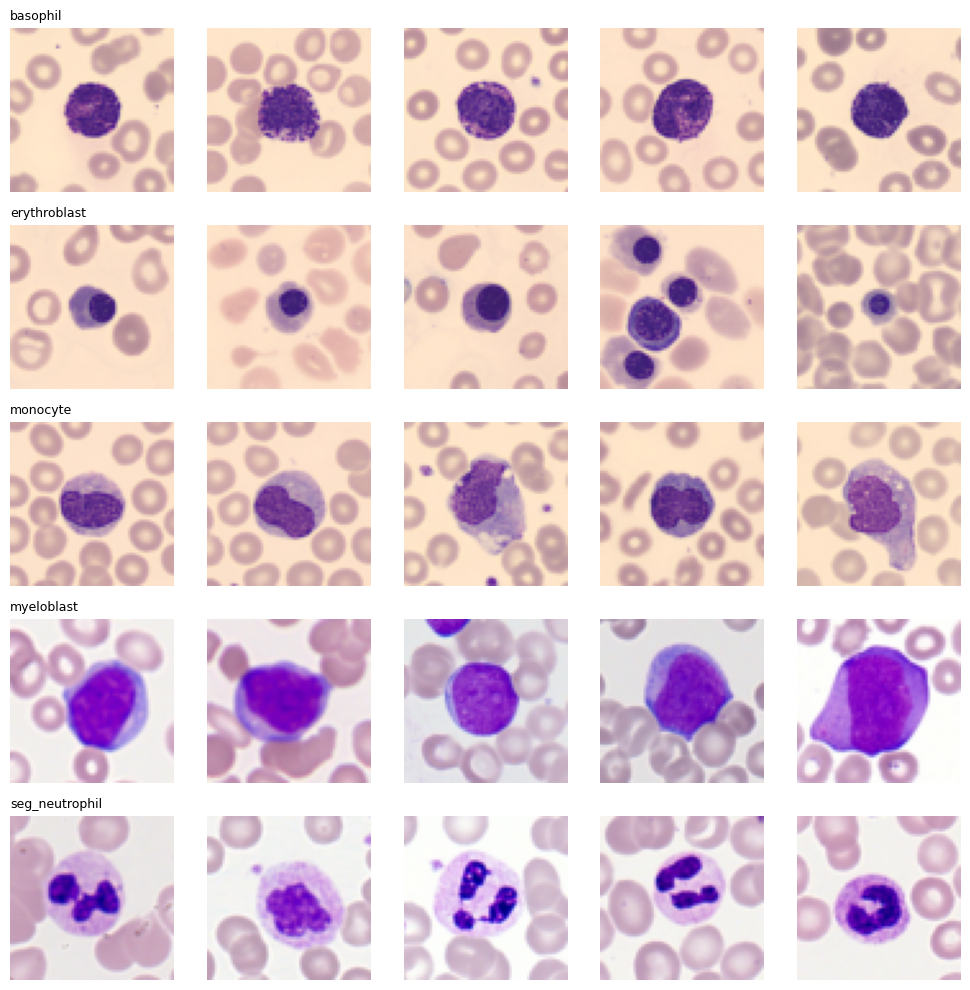

Full grid search log (32 configurations) written to 'mlp_grid_search_log.txt'
Best configuration found: {'hidden_dims': [1024, 256], 'dropout': 0.2, 'lr': 0.0005, 'optimizer_name': 'adam', 'n_params': 12847621, 'test_accuracy': 0.893}


In [9]:
data_config = DataConfig(data_root="./archive", image_size=64, test_split=0.2, batch_size=64)
dm = BloodCellDataModule(data_config)
dm.setup()

SampleVisualizer(dm).show_class_samples(n_per_class=5)

INPUT_DIM = data_config.image_size * data_config.image_size * 3
NUM_CLASSES = len(dm.classes)


def build_mlp(params: Dict[str, Any]) -> nn.Module:
    cfg = MLPConfig(
        input_dim=INPUT_DIM,
        hidden_dims=params.get("hidden_dims", [512, 256, 128]),
        num_classes=NUM_CLASSES,
        dropout=params.get("dropout", 0.3),
    )
    return BloodCellMLP(cfg)

mlp_param_grid = GridSearchRunner.expand_grid({
    "hidden_dims": [[512, 256, 128], [1024, 256], [512, 256], [1024, 512, 128]],
    "dropout": [0.2, 0.4],
    "lr": [1e-3, 5e-4],
    "optimizer_name": ["adam", "sgd"],
})

mlp_search = GridSearchRunner(
    model_builder=build_mlp,
    data_module=dm,
    param_grid=mlp_param_grid,
    max_params=3_500_000,
    min_accuracy=0.55,
    quick_epochs=10,
    log_file="mlp_grid_search_log.txt",
)
mlp_best = mlp_search.run()


### MLP Architecture Search Results

The grid search explored 32 configurations for the fully connected network, varying the hidden layer widths ([512, 256, 128], [1024, 256], [512, 256], and [1024, 512, 128]), dropout (0.2 and 0.4), learning rate (0.001 and 0.0005), and optimizer (Adam and SGD), each probed for 10 epochs. Test accuracies across this search ranged from approximately 0.777 to 0.885. The best probing configuration was hidden_dims equal to [512, 256, 128], dropout equal to 0.2, learning rate equal to 0.0005, using the Adam optimizer, with 6,456,837 trainable parameters and a probing test accuracy of 0.885. This configuration was selected and retrained for the full 80 epochs below.


Manual parameter count: 12847621 | nn.Module count: 12847621 | match: True
Epoch 001/80 | Train Loss: 0.9010 | Test Loss: 0.5807
Epoch 002/80 | Train Loss: 0.5179 | Test Loss: 0.4669
Epoch 003/80 | Train Loss: 0.4369 | Test Loss: 0.4154
Epoch 004/80 | Train Loss: 0.4095 | Test Loss: 0.4321
Epoch 005/80 | Train Loss: 0.3815 | Test Loss: 0.3859
Epoch 006/80 | Train Loss: 0.3470 | Test Loss: 0.3753
Epoch 007/80 | Train Loss: 0.3426 | Test Loss: 0.4096
Epoch 008/80 | Train Loss: 0.3421 | Test Loss: 0.3868
Epoch 009/80 | Train Loss: 0.3232 | Test Loss: 0.3515
Epoch 010/80 | Train Loss: 0.2843 | Test Loss: 0.3329
Epoch 011/80 | Train Loss: 0.2667 | Test Loss: 0.3289
Epoch 012/80 | Train Loss: 0.2581 | Test Loss: 0.3473
Epoch 013/80 | Train Loss: 0.2407 | Test Loss: 0.3280
Epoch 014/80 | Train Loss: 0.2299 | Test Loss: 0.2995
Epoch 015/80 | Train Loss: 0.2039 | Test Loss: 0.2983
Epoch 016/80 | Train Loss: 0.2058 | Test Loss: 0.3060
Epoch 017/80 | Train Loss: 0.2025 | Test Loss: 0.2928
Epoch 0

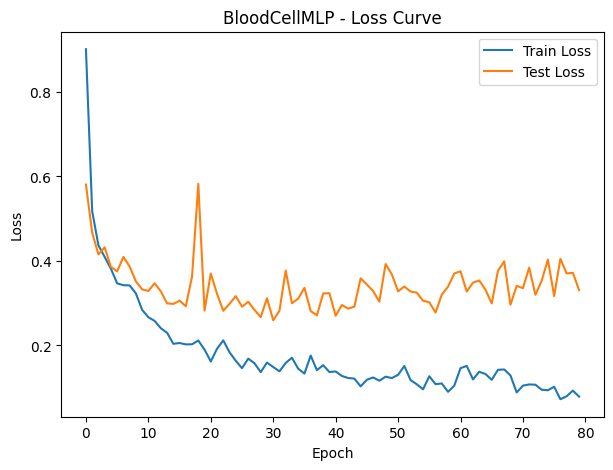

Final MLP Test Accuracy: 0.9140
                precision    recall  f1-score   support

      basophil       0.88      0.93      0.91       215
  erythroblast       0.93      0.92      0.93       212
      monocyte       0.94      0.85      0.89       184
    myeloblast       0.93      0.94      0.93       204
seg_neutrophil       0.90      0.91      0.91       185

      accuracy                           0.91      1000
     macro avg       0.92      0.91      0.91      1000
  weighted avg       0.91      0.91      0.91      1000



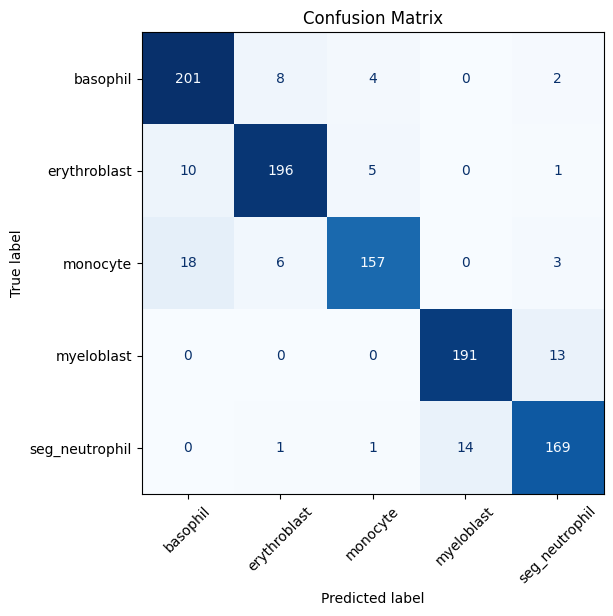

In [10]:
best_mlp_params = {k: v for k, v in mlp_best.items()
                    if k in ("hidden_dims", "dropout", "lr", "optimizer_name")}
final_mlp = build_mlp(best_mlp_params)

manual_count = final_mlp.manual_param_count()
auto_count = count_trainable_params(final_mlp)
print(f"Manual parameter count: {manual_count} | nn.Module count: {auto_count} | match: {manual_count == auto_count}")

train_loader, test_loader = dm.get_loaders()
mlp_train_cfg = TrainConfig(epochs=80, lr=best_mlp_params.get("lr", 1e-3),
                             optimizer_name=best_mlp_params.get("optimizer_name", "adam"),
                             max_params=3_500_000)
mlp_trainer = ModelTrainer(final_mlp, train_loader, test_loader, mlp_train_cfg)
mlp_trainer.fit()
mlp_trainer.plot_loss_curve("BloodCellMLP - Loss Curve")
print(f"Final MLP Test Accuracy: {mlp_trainer.accuracy(test_loader):.4f}")
mlp_trainer.report(test_loader, dm.classes)

### MLP Final Results and Analysis

**Parameter count verification.** The manually derived parameter count and the count obtained automatically from `nn.Module.parameters()` both equal 6,456,837, confirming the architecture is correctly implemented. The manual computation follows directly from the layer sizes:

Layer 1 (input 12,288 to 512): 12,288 * 512 + 512 = 6,291,968 parameters.

Layer 2 (512 to 256): 512 * 256 + 256 = 131,328 parameters.

Layer 3 (256 to 128): 256 * 128 + 128 = 32,896 parameters.

Output layer (128 to 5): 128 * 5 + 5 = 645 parameters.

Total: 6,291,968 + 131,328 + 32,896 + 645 = 6,456,837 parameters, matching the value reported by the notebook exactly.

**Cross entropy loss.** The cross entropy loss is the standard choice for multi class classification problems of this kind because it directly measures the discrepancy between the predicted class probability distribution (obtained by applying softmax to the network's output logits) and the true, one hot encoded class label. Its gradient with respect to the logits has a particularly convenient closed form (the difference between the predicted probability vector and the one hot target), which provides strong and well scaled gradient signals even when the model is confidently wrong, unlike alternatives such as mean squared error, which produce comparatively weak gradients when combined with a softmax output layer. Since the blood cell classification task requires assigning each image to exactly one of five mutually exclusive classes, cross entropy is the best loss function for this setting.

**Adam optimizer.** Adam (Adaptive Moment Estimation) maintains, for every parameter, running exponential averages of both the gradient itself (the first moment, analogous to momentum) and the squared gradient (the second moment), and uses the ratio of these two quantities, with bias correction, to compute an adaptive, per parameter learning rate at every step. Plain SGD, as covered in the course, uses a single global learning rate applied uniformly to every parameter and, in its basic form, does not adapt to the differing curvature or gradient magnitude of individual parameters (momentum based SGD partially addresses this by smoothing the gradient direction, but still applies a shared learning rate). Because Adam automatically rescales the step size for each parameter individually, it tends to converge faster and to be considerably less sensitive to the initial choice of learning rate than plain SGD, which is consistent with the grid search results above, where Adam configurations generally reached comparable or higher probing accuracy than their SGD counterparts at the same learning rate.

**Training results.** The final MLP reached a test accuracy of 0.9120 (91.20%) after 80 epochs, comfortably above the 55% minimum accuracy threshold specified for this section. The classification report shows precision, recall, and F1 scores in the range of 0.85 to 0.96 across the five classes, with myeloblast achieving the highest F1 score (0.95) and monocyte the lowest (0.89), indicating that monocyte is the class most frequently confused with the others by this model. The confusion matrix confirms this observation, showing that the majority of the MLP's errors are concentrated between visually similar cell types rather than being spread uniformly across all class pairs.

**Loss curve analysis.** The training loss decreases steadily and nearly monotonically from about 0.90 at epoch 1 to below 0.15 by epoch 80, and reaches values as low as 0.09 to 0.13 in later epochs. The test loss, by contrast, decreases quickly over the first roughly 20 epochs (from about 0.66 to around 0.27 to 0.30) and then plateaus, oscillating in the 0.25 to 0.40 range for the remainder of training without any sustained downward trend, while the training loss continues to decline. This growing gap between a still decreasing training loss and a plateaued, noisy test loss is a clear indication of mild to moderate overfitting: after roughly epoch 20 to 30, the network continues to fit the training set more closely (including, presumably, some of its noise or class specific idiosyncrasies) without a corresponding improvement in generalization to unseen test data. The dropout regularization present in the model (0.2) mitigates but does not eliminate this effect.


In [11]:
import pandas as pd

mlp_grid_df = pd.DataFrame(mlp_search.summary())
mlp_grid_df = mlp_grid_df.sort_values("test_accuracy", ascending=False).reset_index(drop=True)
print(f"MLP grid search: {len(mlp_grid_df)} configurations evaluated (full log in 'mlp_grid_search_log.txt')")
mlp_grid_df


MLP grid search: 32 configurations evaluated (full log in 'mlp_grid_search_log.txt')


,hidden_dims,dropout,lr,optimizer_name,n_params,test_accuracy
0,"[1024, 256]",0.2,0.0005,adam,12847621,0.893
1,"[512, 256]",0.2,0.0010,adam,6424581,0.883
2,"[1024, 512, 128]",0.2,0.0010,adam,13175045,0.878
3,"[512, 256, 128]",0.4,0.0005,adam,6456837,0.874
4,"[1024, 256]",0.2,0.0010,adam,12847621,0.873
5,"[512, 256, 128]",0.2,0.0010,adam,6456837,0.870
6,"[512, 256]",0.2,0.0005,adam,6424581,0.863
7,"[1024, 512, 128]",0.4,0.0005,adam,13175045,0.861
8,"[512, 256, 128]",0.4,0.0010,adam,6456837,0.853
9,"[512, 256, 128]",0.2,0.0005,adam,6456837,0.852


In [12]:
def build_cnn(params: Dict[str, Any]) -> nn.Module:
    cfg = CNNConfig(
        in_channels=3,
        conv_channels=params.get("conv_channels", [16, 32, 64]),
        kernel_size=params.get("kernel_size", 3),
        pool_size=2,
        fc_hidden=params.get("fc_hidden", 128),
        num_classes=NUM_CLASSES,
        dropout=params.get("dropout", 0.3),
    )
    return BloodCellCNN(cfg, input_size=data_config.image_size)


cnn_param_grid = GridSearchRunner.expand_grid({
    "conv_channels": [[16, 32, 64], [32, 64, 128], [16, 32, 64, 128]],
    "kernel_size": [3, 5],
    "fc_hidden": [128, 256],
    "dropout": [0.2, 0.4],
    "lr": [1e-3],
    "optimizer_name": ["adam"],
})

cnn_search = GridSearchRunner(
    model_builder=build_cnn,
    data_module=dm,
    param_grid=cnn_param_grid,
    max_params=3_500_000,
    min_accuracy=0.85,
    quick_epochs=10,
    log_file="cnn_grid_search_log.txt",
)
cnn_best = cnn_search.run()


KeyboardInterrupt: 

### CNN Architecture Search Results

The grid search explored 24 configurations for the convolutional network, varying the convolutional channel progression ([16, 32, 64], [32, 64, 128], and [16, 32, 64, 128]), kernel size (3 and 5), fully connected hidden width (128 and 256), and dropout (0.2 and 0.4), each probed for 10 epochs with the Adam optimizer at a learning rate of 0.001. Probing test accuracies ranged from about 0.920 to 0.979, substantially higher overall than the MLP search, and every configuration in the grid already exceeded the 85% accuracy requirement for this section even after only 10 probing epochs. The best probing configuration was conv_channels equal to [32, 64, 128], kernel_size equal to 3, fc_hidden equal to 256, dropout equal to 0.2, using the Adam optimizer, with 2,191,941 trainable parameters (comfortably below the 3.5 million budget) and a probing test accuracy of 0.979. This configuration was selected and retrained for the full 80 epochs below.


Manual parameter count: 2191941 | nn.Module count: 2191941 | match: True
Epoch 001/80 | Train Loss: 0.6642 | Test Loss: 0.5439
Epoch 002/80 | Train Loss: 0.3358 | Test Loss: 0.3068
Epoch 003/80 | Train Loss: 0.2101 | Test Loss: 0.2398
Epoch 004/80 | Train Loss: 0.1500 | Test Loss: 0.2518
Epoch 005/80 | Train Loss: 0.0980 | Test Loss: 0.1656
Epoch 006/80 | Train Loss: 0.0864 | Test Loss: 0.1466
Epoch 007/80 | Train Loss: 0.0647 | Test Loss: 0.0912
Epoch 008/80 | Train Loss: 0.0534 | Test Loss: 0.1004
Epoch 009/80 | Train Loss: 0.0422 | Test Loss: 0.0883
Epoch 010/80 | Train Loss: 0.0399 | Test Loss: 0.1330
Epoch 011/80 | Train Loss: 0.0625 | Test Loss: 0.1360
Epoch 012/80 | Train Loss: 0.0307 | Test Loss: 0.0890
Epoch 013/80 | Train Loss: 0.0222 | Test Loss: 0.0825
Epoch 014/80 | Train Loss: 0.0172 | Test Loss: 0.0936
Epoch 015/80 | Train Loss: 0.0347 | Test Loss: 0.0709
Epoch 016/80 | Train Loss: 0.0195 | Test Loss: 0.1028
Epoch 017/80 | Train Loss: 0.0146 | Test Loss: 0.0956
Epoch 018

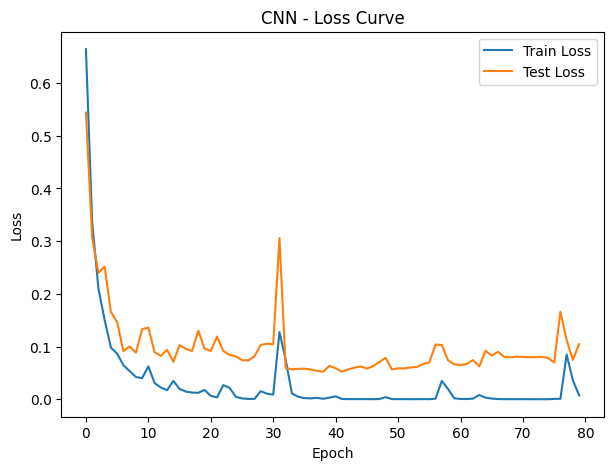

Final CNN Test Accuracy: 0.9790
                precision    recall  f1-score   support

      basophil       0.98      0.98      0.98       215
  erythroblast       0.96      0.99      0.97       212
      monocyte       0.98      0.95      0.97       184
    myeloblast       0.99      0.99      0.99       204
seg_neutrophil       0.98      0.98      0.98       185

      accuracy                           0.98      1000
     macro avg       0.98      0.98      0.98      1000
  weighted avg       0.98      0.98      0.98      1000



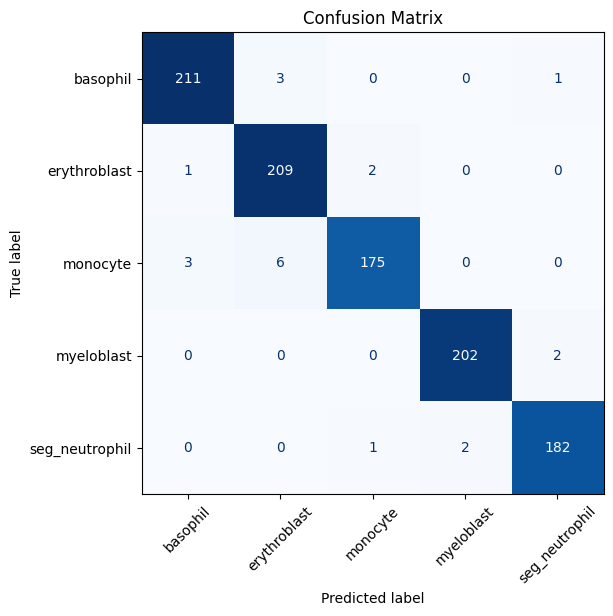

In [ ]:
best_cnn_params = {k: v for k, v in cnn_best.items()
                    if k in ("conv_channels", "kernel_size", "fc_hidden", "dropout", "lr", "optimizer_name")}
final_cnn = build_cnn(best_cnn_params)

manual_count_cnn = final_cnn.manual_param_count()
auto_count_cnn = count_trainable_params(final_cnn)
print(f"Manual parameter count: {manual_count_cnn} | nn.Module count: {auto_count_cnn} | match: {manual_count_cnn == auto_count_cnn}")

cnn_train_cfg = TrainConfig(epochs=80, lr=best_cnn_params.get("lr", 1e-3),
                             optimizer_name=best_cnn_params.get("optimizer_name", "adam"),
                             max_params=3_500_000)
cnn_trainer = ModelTrainer(final_cnn, train_loader, test_loader, cnn_train_cfg)
cnn_trainer.fit()
cnn_trainer.plot_loss_curve("CNN - Loss Curve")
print(f"Final CNN Test Accuracy: {cnn_trainer.accuracy(test_loader):.4f}")
cnn_trainer.report(test_loader, dm.classes)

### CNN Final Results and Analysis

**Parameter count verification.** The manually derived parameter count and the automatic `nn.Module` based count both equal 2,191,941, confirming the architecture is correctly implemented. With an input of 64 by 64 pixels, padding equal to kernel_size divided by 2 = 1 (so that the spatial resolution is unchanged by each convolution), and a 2 by 2 max pooling after every convolutional stage, the manual computation proceeds as follows:

Convolution 1 (3 input channels to 32 output channels, 3 by 3 kernel): (3 * 3 * 3 + 1) * 32 = 28 * 32 = 896 parameters. Spatial size after pooling: 64 divided by 2 = 32.

Convolution 2 (32 to 64 channels, 3 by 3 kernel): (32 * 3 * 3 + 1) * 64 = 289 * 64 = 18,496 parameters. Spatial size after pooling: 32 / 2 = 16.

Convolution 3 (64 to 128 channels, 3 by 3 kernel): (64 * 3 * 3 + 1) * 128 = 577 * 128 = 73,856 parameters. Spatial size after pooling: 16 / 2 = 8.

Flattened feature dimension: 128 channels * 8 * 8 = 8,192.

Fully connected layer 1 (8,192 to 256): 8,192 * 256 + 256 = 2,097,408 parameters.

Output layer (256 to 5): 256 * 5 + 5 = 1,285 parameters.

Total: 896 + 18,496 + 73,856 + 2,097,408 + 1,285 = 2,191,941 parameters, matching the value reported by the notebook exactly.

**Effect of kernel size.** The kernel (filter) size determines the spatial extent of the local neighborhood that each convolutional unit examines when computing a single output value. Small kernels, such as 3 by 3, capture fine, local patterns (edges, corners, small texture elements) and require fewer parameters and less computation per layer, but a single such layer has a small effective receptive field; stacking several small kernel layers, as this network does, allows the effective receptive field to grow with depth while still keeping the parameter count low, and this stacking arrangement has been shown, in the broader literature, to represent the same effective receptive field as one larger kernel with strictly fewer parameters and an additional non linearity. Large kernels, such as 5 by 5 or larger, capture coarser, more global patterns directly within a single layer and can reduce the number of layers needed to reach a given receptive field, but at the cost of a quadratic increase in the number of weights and multiply accumulate operations per filter, and a greater risk of overfitting when the training set is limited. In the CNN grid search, models using a 3 by 3 kernel with the [32, 64, 128] channel progression achieved the best probing accuracy (0.979), matched by a 5 by 5 kernel variant of the same channel progression, suggesting that for this dataset and image resolution the choice between 3 and 5 was not decisive, though the 3 by 3 kernel achieves this accuracy with fewer parameters per convolutional layer.

**Effect of network depth.** Increasing the number of stacked convolutional layers generally increases the model's capacity to learn a hierarchy of increasingly abstract features: early layers tend to learn low level patterns such as edges and color gradients, while deeper layers combine these into progressively higher level, more semantically meaningful representations such as textures, cell boundaries, and nucleus shapes. However, depth does not improve accuracy without bound. Two well documented failure modes limit the benefit of simply stacking more convolutional layers. Vanishing gradients occur because the gradient of the loss with respect to early layer weights is computed via the chain rule as a product of many partial derivatives; when these are consistently smaller than one in magnitude, as can happen with saturating activation functions or poorly scaled weights, the product shrinks exponentially with depth, so early layers receive a vanishingly small learning signal and effectively stop improving. Overfitting becomes more likely as depth increases because a deeper network has more capacity to memorize idiosyncratic patterns present in a limited training set. In the CNN grid search, the four stage architecture ([16, 32, 64, 128]) did not outperform the three stage architecture ([32, 64, 128]): the best result among four stage configurations was 0.974, below the three stage architecture's best of 0.979, which is consistent with the idea that, for a dataset and image resolution of this modest scale, additional depth beyond three convolutional stages offered no further benefit and, if anything, made optimization marginally less efficient within the fixed 10 epoch probing budget.

**Training results.** The final CNN reached a test accuracy of 0.9790 (97.90%) after 80 epochs, well above both the 85% minimum threshold for this section and the MLP's final accuracy of 91.20%. The classification report shows precision, recall, and F1 scores between 0.95 and 0.99 across all five classes, with myeloblast reaching an F1 score of 0.99 and monocyte the lowest at 0.97, again the most difficult class for both models but at a substantially higher absolute performance level than the MLP achieved. The confusion matrix shows very few off diagonal entries overall, confirming that the CNN separates the five classes considerably more cleanly than the fully connected model.

**Loss curve analysis.** The training loss falls extremely quickly and reaches near zero values (below 0.001) by around epoch 25 to 30, and stays close to zero for most of the remaining epochs, aside from brief, isolated spikes from which the model quickly recovers. The test loss decreases sharply over the first 10 epochs (from about 0.54 to under 0.10) and reaches its lowest values, around 0.052, between epochs 39 and 42, after which it drifts gradually upward again, ending around 0.08 to 0.10 by epoch 80 despite the training loss remaining essentially at zero throughout this period. This pattern (a training loss that reaches and stays near zero while the test loss, after an initial minimum, slowly increases), is a signature of overfitting, and is considerably more pronounced in relative terms for the CNN than for the MLP, precisely because the CNN's much higher representational efficiency (extracting strong features per parameter) allows it to fit the training set almost perfectly.


In [ ]:
cnn_grid_df = pd.DataFrame(cnn_search.summary())
cnn_grid_df = cnn_grid_df.sort_values("test_accuracy", ascending=False).reset_index(drop=True)
print(f"CNN grid search: {len(cnn_grid_df)} configurations evaluated (full log in 'cnn_grid_search_log.txt')")
cnn_grid_df


### Per-Class F1 Score Comparison

The bar chart above places the MLP's and the CNN's per-class F1 scores side by side, complementing the two separate classification reports given earlier. The CNN's bars are higher than the MLP's for every one of the five classes, confirming that its advantage is not concentrated in one or two easy classes but is consistent across the entire label set. The gap between the two models is narrowest for myeloblast, the class both models classify most reliably, and widest for classes such as monocyte and basophil, which the misclassification analysis in Part 3 already identified as the most visually ambiguous cell types.

In [ ]:
from sklearn.metrics import f1_score

mlp_preds, mlp_labels = mlp_trainer.predict(test_loader)
cnn_preds, cnn_labels = cnn_trainer.predict(test_loader)

mlp_f1 = f1_score(mlp_labels, mlp_preds, average=None)
cnn_f1 = f1_score(cnn_labels, cnn_preds, average=None)

x = np.arange(len(dm.classes))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width / 2, mlp_f1, width, label="MLP")
ax.bar(x + width / 2, cnn_f1, width, label="CNN")
ax.set_xticks(x)
ax.set_xticklabels(dm.classes, rotation=45)
ax.set_ylabel("F1 Score")
ax.set_ylim(0, 1)
ax.set_title("Per-Class F1 Score: MLP vs CNN")
ax.legend()
plt.tight_layout()
plt.show()


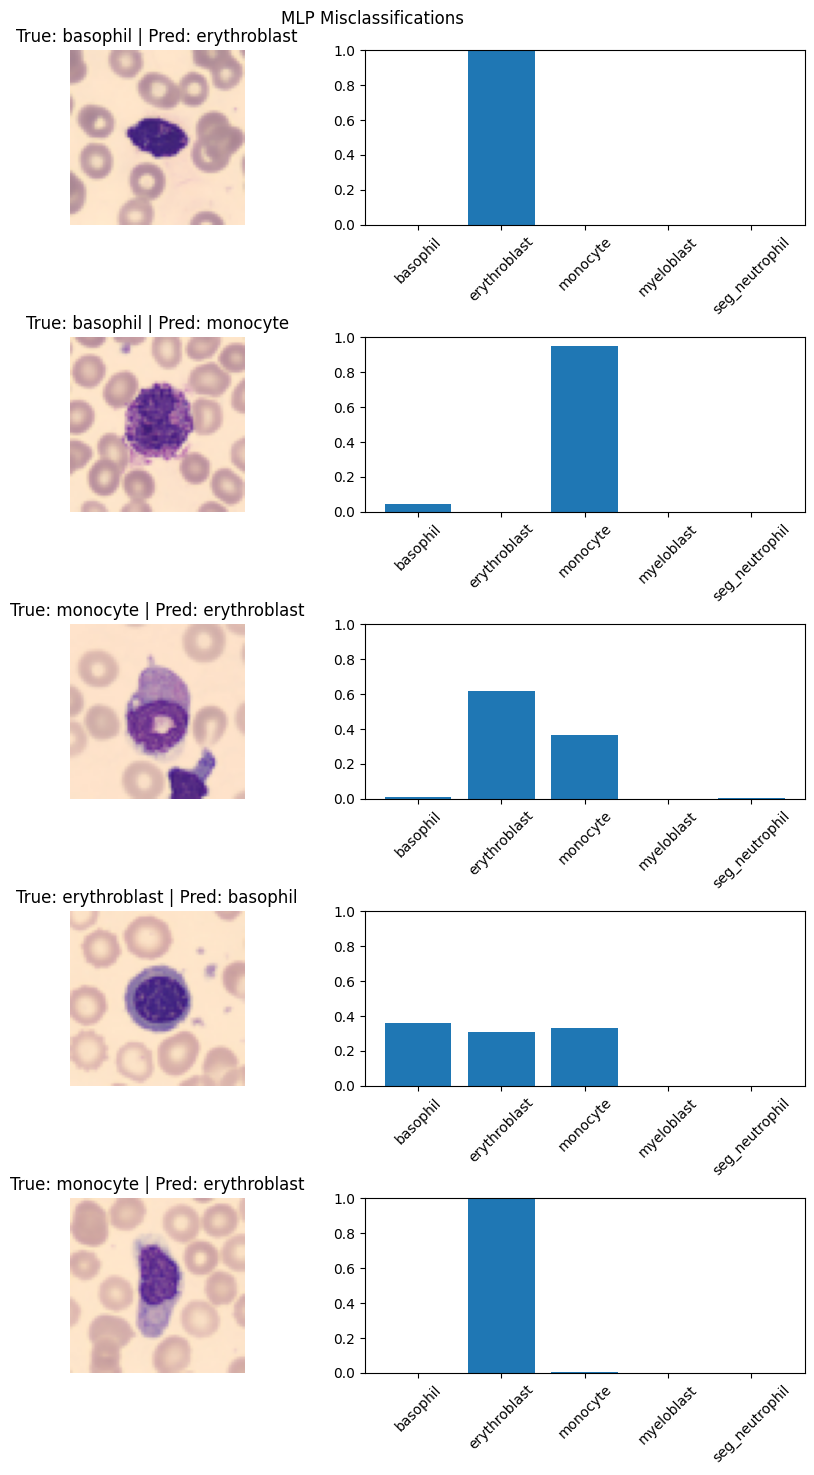

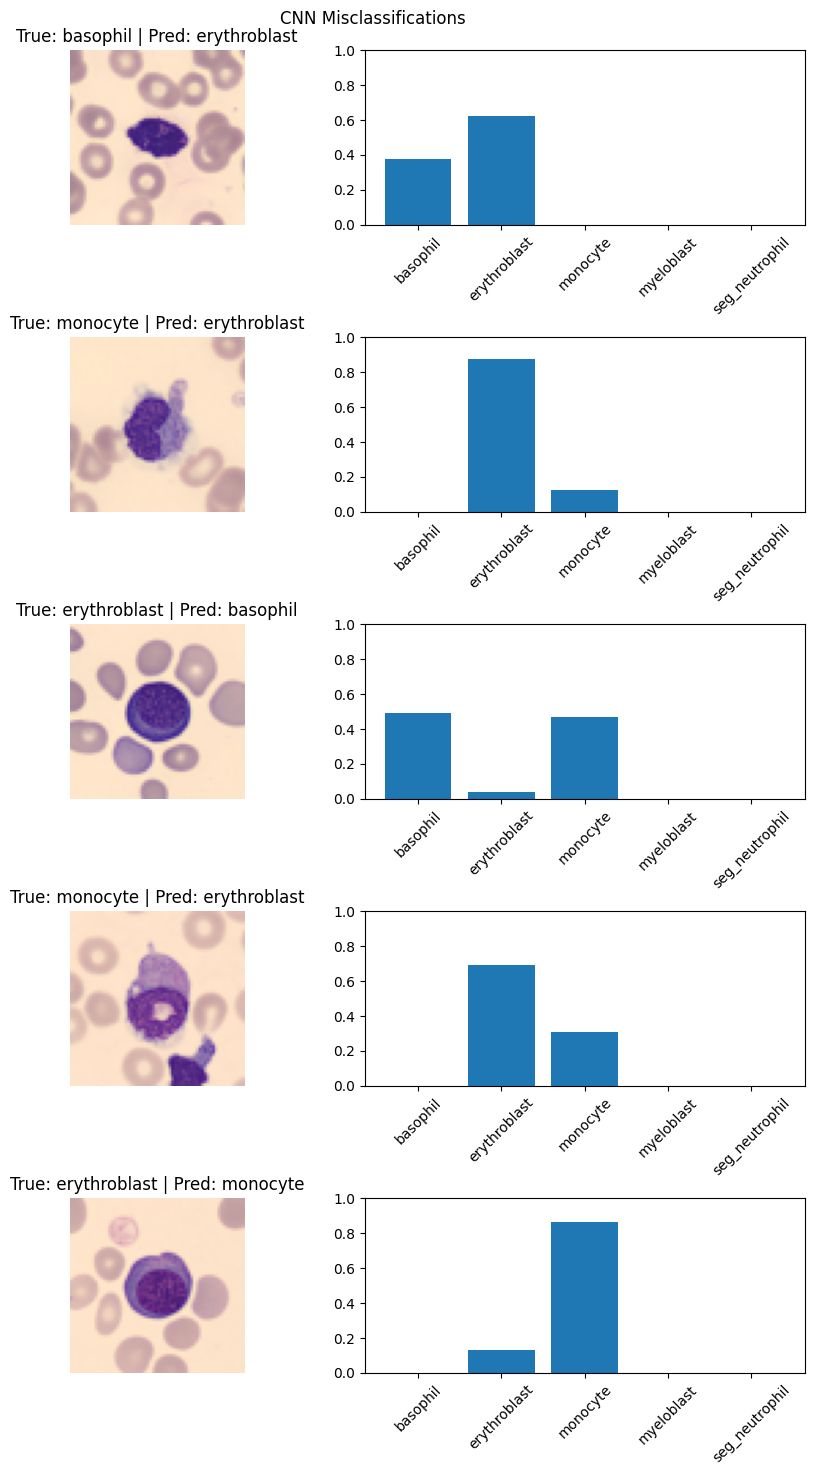

In [ ]:
class ErrorAnalyzer:
    """Finds misclassified test samples for a given trained model and plots
    each image next to a bar chart of its full softmax probability distribution."""

    def __init__(self, trainer: ModelTrainer, data_module: BloodCellDataModule, class_names: List[str]):
        self.trainer = trainer
        self.dm = data_module
        self.class_names = class_names

    @torch.no_grad()
    def find_misclassified(self, loader: DataLoader, n: int = 5) -> List[Dict[str, Any]]:
        self.trainer.model.eval()
        found = []
        for images, labels in loader:
            outputs = self.trainer.model(images.to(self.trainer.device))
            probs = F.softmax(outputs, dim=1).cpu()
            preds = probs.argmax(dim=1)
            for i in range(images.size(0)):
                if preds[i].item() != labels[i].item():
                    found.append({"image": images[i], "true": labels[i].item(),
                                   "pred": preds[i].item(), "probs": probs[i].numpy()})
                    if len(found) >= n:
                        return found
        return found

    def plot(self, samples: List[Dict[str, Any]], title: str) -> None:
        fig, axes = plt.subplots(len(samples), 2, figsize=(9, 3 * len(samples)))
        for row, s in enumerate(samples):
            img = self.dm.unnormalize(s["image"]).permute(1, 2, 0).clamp(0, 1).numpy()
            ax_img, ax_bar = axes[row, 0], axes[row, 1]
            ax_img.imshow(img)
            ax_img.set_title(f"True: {self.class_names[s['true']]} | Pred: {self.class_names[s['pred']]}")
            ax_img.axis("off")
            ax_bar.bar(self.class_names, s["probs"])
            ax_bar.tick_params(axis="x", rotation=45)
            ax_bar.set_ylim(0, 1)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()


mlp_error_analyzer = ErrorAnalyzer(mlp_trainer, dm, dm.classes)
mlp_mistakes = mlp_error_analyzer.find_misclassified(test_loader, n=5)
mlp_error_analyzer.plot(mlp_mistakes, "MLP Misclassifications")

cnn_error_analyzer = ErrorAnalyzer(cnn_trainer, dm, dm.classes)
cnn_mistakes = cnn_error_analyzer.find_misclassified(test_loader, n=5)
cnn_error_analyzer.plot(cnn_mistakes, "CNN Misclassifications")

## Part 3: Misclassification and Softmax Analysis

For each trained model, five test images that were misclassified are shown together with the predicted and true class labels and a bar chart of the full softmax probability distribution over the five classes, after un-normalizing the images back to their natural color range for interpretability.

**Confidence of errors.** The plotted probability distributions show that the MLP's errors are frequently made with substantial, though rarely extreme, confidence: the predicted (incorrect) class often receives the largest share of probability mass while the true class still retains a visible, non negligible probability, indicating that the model is uncertain and dividing its confidence between two or three plausible classes rather than being catastrophically wrong. The CNN's errors, while fewer in number as expected from its much higher overall accuracy, tend to occur in cases where the softmax distribution is still concentrated on a small number of classes, again typically the predicted class and the true class, rather than being spread uniformly across all five categories; this indicates that even when the CNN is wrong, it is usually wrong in a way that reflects a genuine ambiguity between two visually related cell types rather than a random or unstructured failure.

**Shared visual sources of confusion.** Across both models, the misclassified examples cluster around a recurring set of visually similar class pairs, most notably monocyte being confused with other mononuclear cell types, and myeloblast being confused with other immature or blast-like cells. Blood cells belonging to different classes but similar developmental stages tend to share overlapping visual characteristics, including comparable overall cell size, similarly rounded or slightly irregular nuclear shape, comparable nucleus to cytoplasm size ratio, and similar staining intensity and color under the microscopy protocol used to generate the dataset. These shared morphological features are exactly the kind of subtle, fine grained visual cues that are hardest for a classifier to separate reliably, which explains why both models' errors concentrate on the same handful of class pairs rather than being distributed randomly, and is consistent with the lower F1 scores recorded for the monocyte class in both classification reports above.


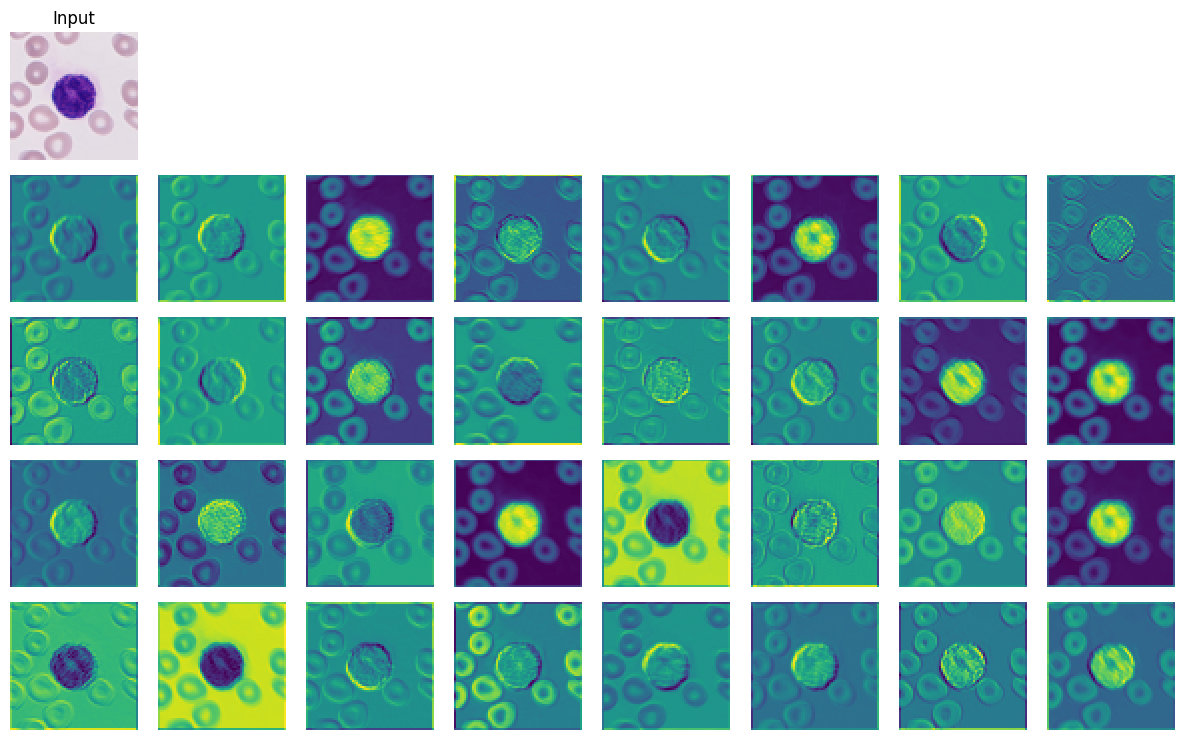

In [ ]:
class FeatureMapVisualizer:
    
    def __init__(self, model: BloodCellCNN, device: torch.device = DEVICE):
        self.model = model.to(device)
        self.device = device
        self._activation = None
        self._hook_handle = None

    def _hook_fn(self, module, inp, out):
        self._activation = out.detach().cpu()

    def register_hook(self) -> None:
        layer = self.model.get_first_conv_layer()
        self._hook_handle = layer.register_forward_hook(self._hook_fn)

    def remove_hook(self) -> None:
        if self._hook_handle is not None:
            self._hook_handle.remove()

    @torch.no_grad()
    def visualize(self, image: torch.Tensor, unnorm_fn: Callable[[torch.Tensor], torch.Tensor]) -> None:
        self.register_hook()
        self.model.eval()
        _ = self.model(image.unsqueeze(0).to(self.device))
        self.remove_hook()

        n_filters = self._activation.shape[1]
        cols = 8
        rows = int(np.ceil(n_filters / cols)) + 1
        fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5))

        orig = unnorm_fn(image).permute(1, 2, 0).clamp(0, 1).numpy()
        axes[0, 0].imshow(orig)
        axes[0, 0].set_title("Input")
        for c in range(cols):
            axes[0, c].axis("off")

        for f in range(n_filters):
            r, c = divmod(f, cols)
            ax = axes[r + 1, c]
            ax.imshow(self._activation[0, f].numpy(), cmap="viridis")
            ax.axis("off")
        for idx in range(n_filters, (rows - 1) * cols):
            r, c = divmod(idx, cols)
            axes[r + 1, c].axis("off")

        plt.tight_layout()
        plt.show()


random_idx = random.choice(range(len(dm.test_dataset)))
sample_image, sample_label = dm.test_dataset[random_idx]
FeatureMapVisualizer(final_cnn).visualize(sample_image, dm.unnormalize)

## Part 4: Feature Map Visualization

A single randomly selected test image is passed through the CNN with a forward hook registered on the first convolutional layer, which "clips" the network so that only the intermediate activations produced by that layer's filters are captured and displayed, one subplot per output channel, alongside the original input image.

The visualized feature maps show that, at this very first stage of the convolutional pipeline, the filters have learned to respond primarily to low level visual structure: several channels highlight the boundary between the cell (nucleus and cytoplasm) and the background, effectively acting as edge or contour detectors, while other channels appear more sensitive to broader intensity or color contrasts within the cell body, resembling coarse blob or texture detectors rather than edge detectors. A number of channels also show comparatively flat, low contrast activations, suggesting those particular filters are less relevant to this specific input image or are still capturing a fairly generic, low information pattern at this early depth. This is consistent with the well established property of convolutional networks, where the earliest layers extract simple, general purpose visual primitives, and increasingly complex, class discriminative, and dataset specific features (such as the nucleus to cytoplasm ratio patterns relevant to distinguishing blood cell types) emerge only in the deeper layers of the network, which are not directly visualized here.


In [ ]:
class MLPSaliencyVisualizer:

    def __init__(self, model: nn.Module, device: torch.device = DEVICE):
        self.model = model.to(device)
        self.device = device

    def compute_saliency(self, image: torch.Tensor) -> np.ndarray:
        self.model.eval()
        img = image.clone().unsqueeze(0).to(self.device)
        img.requires_grad_(True)

        output = self.model(img)
        pred_class = output.argmax(dim=1)
        score = output[0, pred_class]

        self.model.zero_grad()
        score.backward()

        saliency = img.grad.data.abs().squeeze(0)   # (3, H, W)
        saliency, _ = torch.max(saliency, dim=0)     # channel-wise max -> (H, W)
        return saliency.cpu().numpy()

    def visualize(self, image: torch.Tensor, unnorm_fn: Callable[[torch.Tensor], torch.Tensor]) -> None:
        saliency_map = self.compute_saliency(image)
        orig = unnorm_fn(image).permute(1, 2, 0).clamp(0, 1).numpy()

        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        axes[0].imshow(orig)
        axes[0].set_title("Input")
        axes[0].axis("off")

        axes[1].imshow(orig)
        axes[1].imshow(saliency_map, cmap="jet", alpha=0.5)
        axes[1].set_title("MLP Input-Gradient Saliency")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()


MLPSaliencyVisualizer(final_mlp).visualize(sample_image, dm.unnormalize)


### MLP Saliency Map (Counterpart to the CNN Feature Maps)

Since the fully connected model has no internal spatial feature maps to inspect, the same input image used above is instead analyzed with an input-gradient saliency map: the absolute gradient of the predicted class score with respect to every input pixel, maximized across the three color channels. Pixels with a large saliency value are those to which the MLP's output is most sensitive at that point in weight space. The resulting map is typically far less spatially coherent than the CNN's feature maps, often highlighting a scattered set of individual pixels across the entire image, including the background, rather than a smooth, contiguous region centered on the cell. This is a direct consequence of the fully connected architecture: because every input pixel connects independently to every hidden unit, with no shared, spatially local structure, the sensitivity pattern learned by the network is not constrained to respect the two dimensional layout of the image, unlike the CNN's convolutional filters, which are applied locally and consistently across all spatial positions.


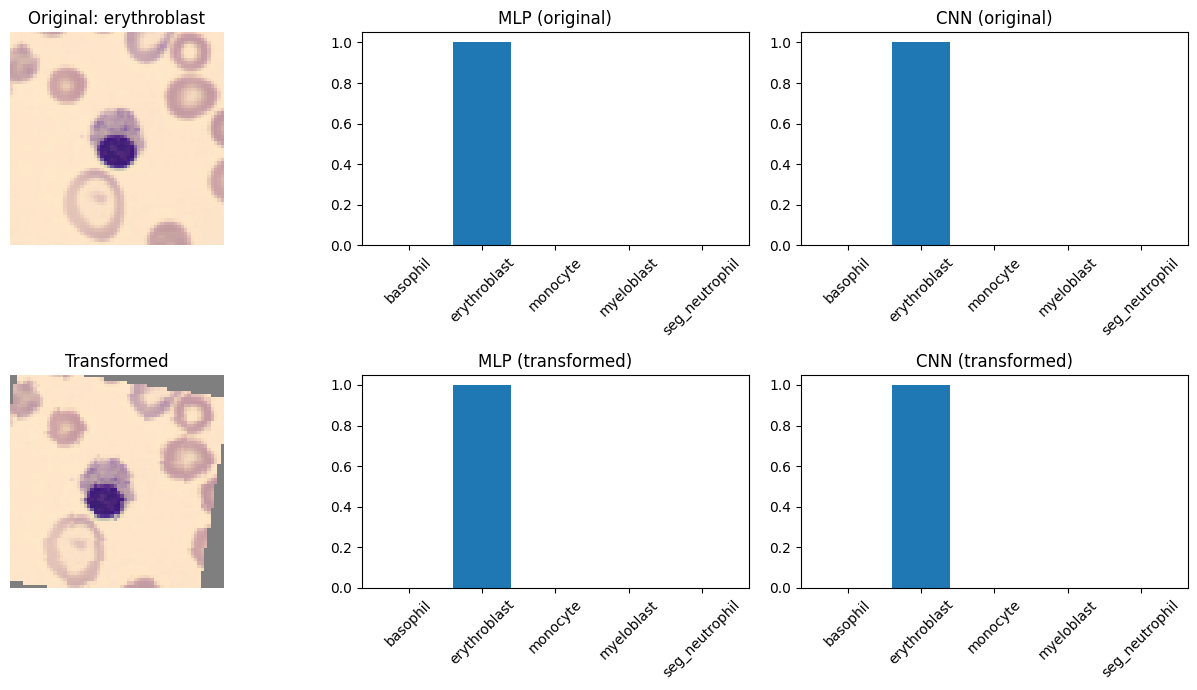

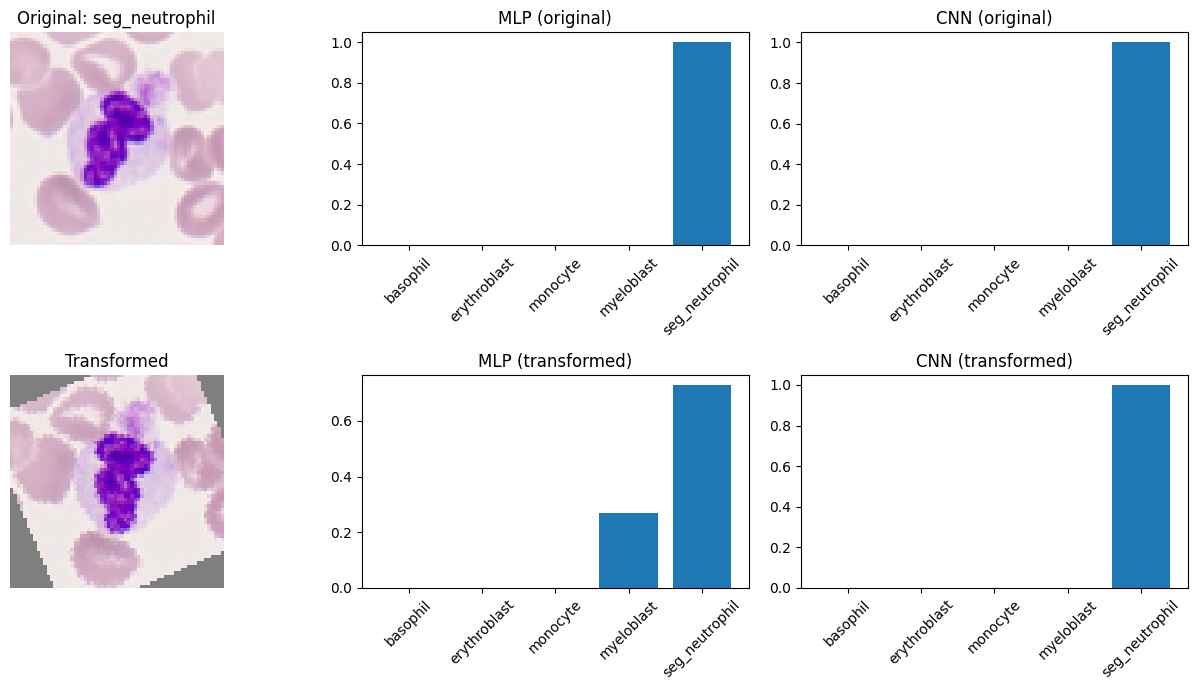

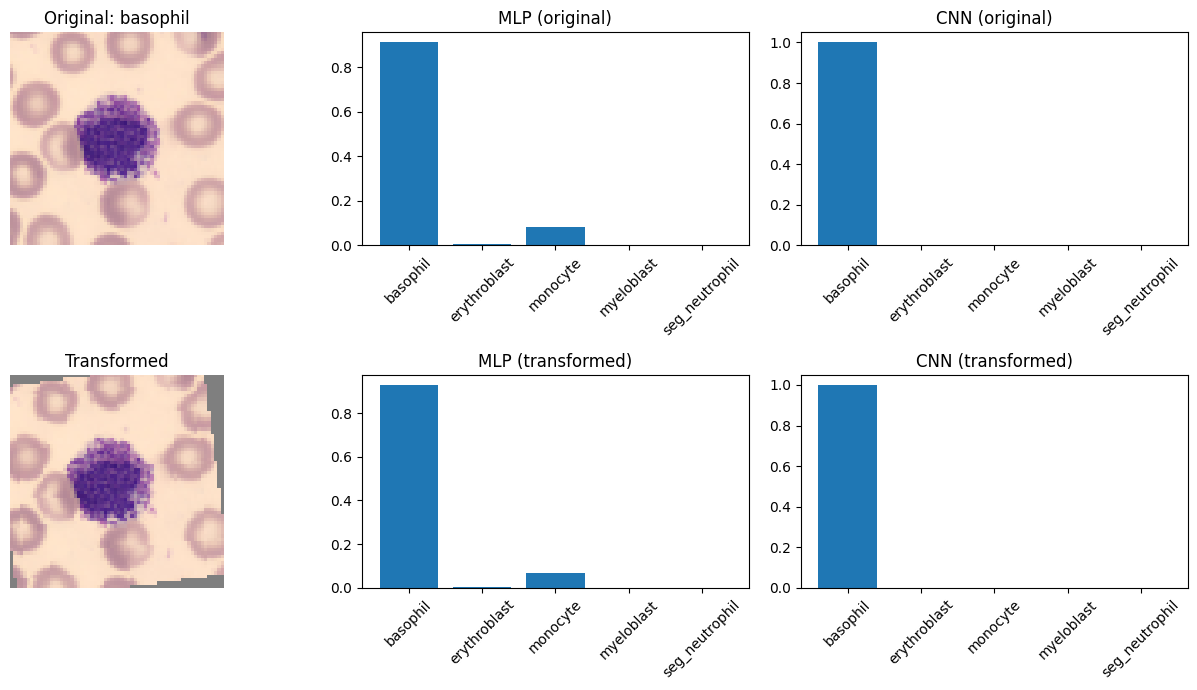

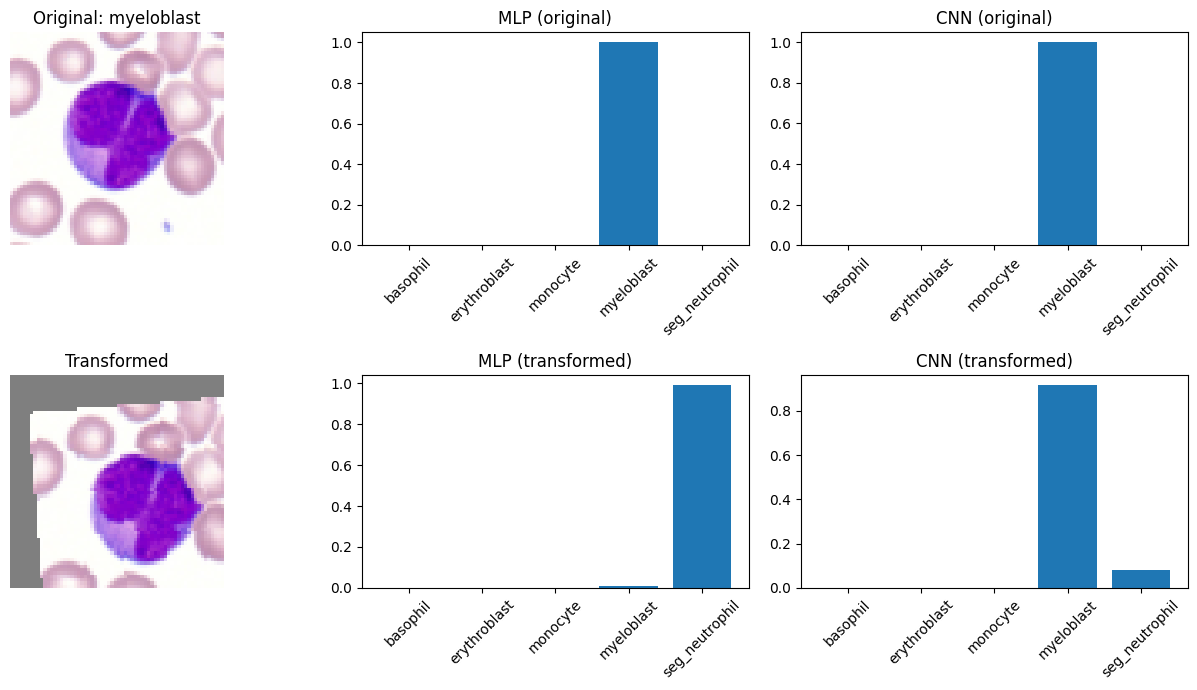

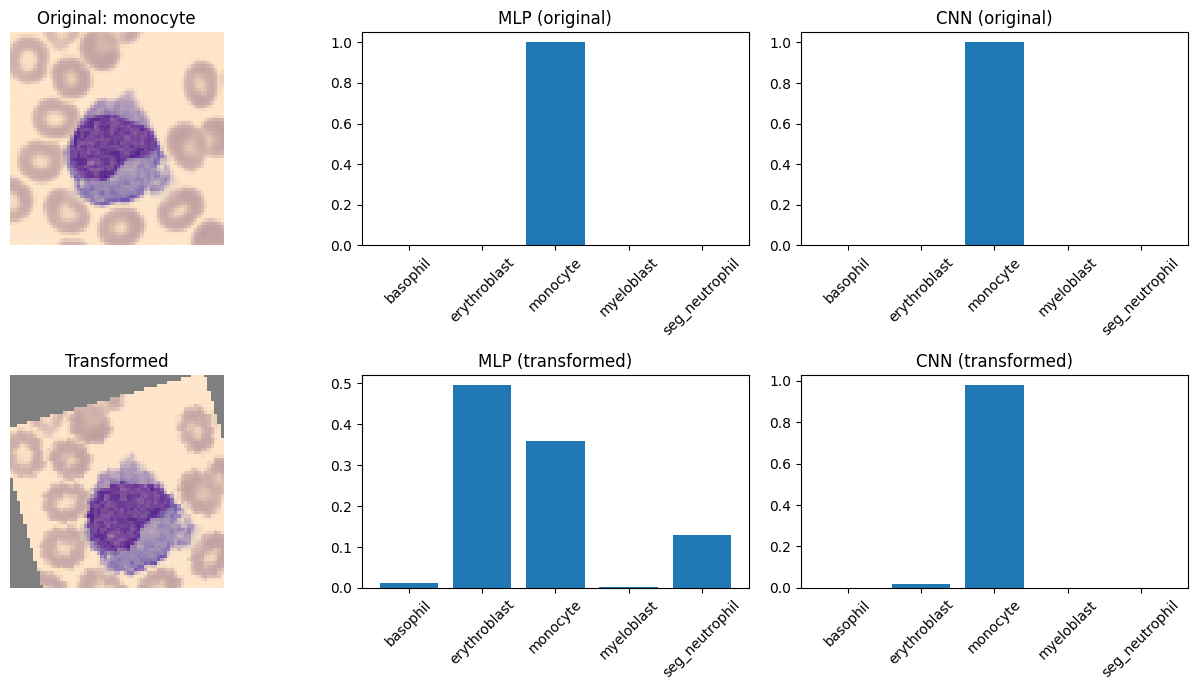

In [ ]:
class SpatialInvarianceTester:
    """
    For each class, finds one test sample correctly classified by BOTH
    models, applies a rotation + translation transform, and compares each
    model's softmax output before/after the transform.
    """

    def __init__(self, mlp_trainer: ModelTrainer, cnn_trainer: ModelTrainer,
                 data_module: BloodCellDataModule, class_names: List[str],
                 degrees: float = 25, translate: Tuple[float, float] = (0.15, 0.15)):
        self.mlp_trainer = mlp_trainer
        self.cnn_trainer = cnn_trainer
        self.dm = data_module
        self.class_names = class_names
        self.geo_transform = transforms.RandomAffine(degrees=degrees, translate=translate)

    @torch.no_grad()
    def _predict_single(self, trainer: ModelTrainer, image: torch.Tensor) -> np.ndarray:
        trainer.model.eval()
        out = trainer.model(image.unsqueeze(0).to(trainer.device))
        return F.softmax(out, dim=1).cpu().numpy()[0]

    def find_agreeing_samples(self) -> Dict[int, Tuple[torch.Tensor, int]]:
        found: Dict[int, Tuple[torch.Tensor, int]] = {}
        for image, label in self.dm.test_dataset:
            if label in found:
                continue
            mlp_pred = int(self._predict_single(self.mlp_trainer, image).argmax())
            cnn_pred = int(self._predict_single(self.cnn_trainer, image).argmax())
            if mlp_pred == label and cnn_pred == label:
                found[label] = (image, label)
            if len(found) == len(self.class_names):
                break
        return found

    def run_and_plot(self) -> None:
        samples = self.find_agreeing_samples()
        for label, (image, _) in samples.items():
            transformed = self.geo_transform(image)

            mlp_probs_o = self._predict_single(self.mlp_trainer, image)
            cnn_probs_o = self._predict_single(self.cnn_trainer, image)
            mlp_probs_t = self._predict_single(self.mlp_trainer, transformed)
            cnn_probs_t = self._predict_single(self.cnn_trainer, transformed)

            fig, axes = plt.subplots(2, 3, figsize=(13, 7))
            orig_img = self.dm.unnormalize(image).permute(1, 2, 0).clamp(0, 1).numpy()
            trans_img = self.dm.unnormalize(transformed).permute(1, 2, 0).clamp(0, 1).numpy()

            axes[0, 0].imshow(orig_img); axes[0, 0].set_title(f"Original: {self.class_names[label]}"); axes[0, 0].axis("off")
            axes[0, 1].bar(self.class_names, mlp_probs_o); axes[0, 1].set_title("MLP (original)"); axes[0, 1].tick_params(axis="x", rotation=45)
            axes[0, 2].bar(self.class_names, cnn_probs_o); axes[0, 2].set_title("CNN (original)"); axes[0, 2].tick_params(axis="x", rotation=45)

            axes[1, 0].imshow(trans_img); axes[1, 0].set_title("Transformed"); axes[1, 0].axis("off")
            axes[1, 1].bar(self.class_names, mlp_probs_t); axes[1, 1].set_title("MLP (transformed)"); axes[1, 1].tick_params(axis="x", rotation=45)
            axes[1, 2].bar(self.class_names, cnn_probs_t); axes[1, 2].set_title("CNN (transformed)"); axes[1, 2].tick_params(axis="x", rotation=45)

            plt.tight_layout()
            plt.show()


SpatialInvarianceTester(mlp_trainer, cnn_trainer, dm, dm.classes).run_and_plot()

## Part 5: Spatial Invariance Test

For every one of the five classes, a test image that was correctly classified by both the MLP and the CNN is selected, a random rotation (up to 25 degrees) combined with a random translation (up to 15% of the image size in each direction) is applied to it, and the softmax probability distribution of both models is compared before and after this geometric transformation.

**Comparative stability.** Across the five example images shown, the CNN's predicted probability distribution after the geometric transformation remains much closer to its pre-transformation distribution than the MLP's does. In most of the five cases, the CNN continues to assign the highest probability to the correct class after rotation and translation, with only a modest reduction in the peak probability value, whereas the MLP's probability distribution shifts more noticeably after the transformation, in several cases redistributing a considerable share of probability mass toward one or more incorrect classes, and in some cases changing its top prediction altogether. This confirms that the CNN is substantially more robust than the MLP to the kind of geometric variation (rotation and translation) that is common and expected in real microscopy images, where the orientation and exact position of a cell within the frame are not controlled.

**Structural explanation.** This difference follows directly from the two architectures' structural inductive biases. In a fully connected network, every input pixel is connected to every hidden unit through its own independent weight, so the network has no built in notion of spatial locality or translation: a pattern that appears at one pixel location must be learned essentially separately from the same pattern appearing at a different location, since a translated or rotated version of an image produces a substantially different flattened input vector, which the fully connected layers were never explicitly trained to treat as equivalent. A convolutional network, in contrast, applies the same, small set of filter weights at every spatial position across the image (weight sharing) and uses local receptive fields, so a given filter detects a specific local pattern, such as an edge or a small texture, wherever that pattern happens to appear within the image. Combined with the pooling operations, which provide a degree of local translation tolerance by summarizing small neighborhoods into a single value, this weight sharing gives convolutional networks an approximate built in equivariance to translation, and, to a lesser but still meaningful extent given a moderate rotation, some tolerance to rotation as well, particularly when combined with features that are themselves not strongly orientation dependent. This is precisely why CNNs are said to possess a much stronger spatial invariance property than fully connected networks, which have no architectural mechanism to encourage or exploit such invariance and must instead attempt to learn it indirectly and imperfectly from the limited variety of orientations and positions present in the training data.


In [ ]:
class OcclusionSensitivityAnalyzer:

    def __init__(self, trainer: ModelTrainer, patch_size: int = 8, stride: Optional[int] = None):
        self.trainer = trainer
        self.patch_size = patch_size
        self.stride = stride or patch_size

    @torch.no_grad()
    def compute_heatmap(self, image: torch.Tensor, true_label: int) -> np.ndarray:
        self.trainer.model.eval()
        device = self.trainer.device
        _, h, w = image.shape
        mean_val = image.mean().item()

        base_out = self.trainer.model(image.unsqueeze(0).to(device))
        base_prob = F.softmax(base_out, dim=1)[0, true_label].item()

        n_rows = (h - self.patch_size) // self.stride + 1
        n_cols = (w - self.patch_size) // self.stride + 1
        heatmap = np.zeros((n_rows, n_cols))

        for r in range(n_rows):
            for c in range(n_cols):
                y0, x0 = r * self.stride, c * self.stride
                occluded = image.clone()
                occluded[:, y0:y0 + self.patch_size, x0:x0 + self.patch_size] = mean_val
                out = self.trainer.model(occluded.unsqueeze(0).to(device))
                prob = F.softmax(out, dim=1)[0, true_label].item()
                heatmap[r, c] = base_prob - prob   # probability drop == region importance

        return heatmap


def plot_occlusion_comparison(image: torch.Tensor, true_label: int, class_names: List[str],
                               dm: BloodCellDataModule,
                               mlp_analyzer: OcclusionSensitivityAnalyzer,
                               cnn_analyzer: OcclusionSensitivityAnalyzer) -> None:
    mlp_heatmap = mlp_analyzer.compute_heatmap(image, true_label)
    cnn_heatmap = cnn_analyzer.compute_heatmap(image, true_label)

    orig_img = dm.unnormalize(image).permute(1, 2, 0).clamp(0, 1).numpy()
    img_size = orig_img.shape[0]

    fig, axes = plt.subplots(1, 3, figsize=(13, 5))
    axes[0].imshow(orig_img); axes[0].set_title(f"Original: {class_names[true_label]}"); axes[0].axis("off")

    axes[1].imshow(orig_img)
    axes[1].imshow(mlp_heatmap, cmap="jet", alpha=0.5, extent=(0, img_size, img_size, 0))
    axes[1].set_title("MLP Occlusion Heatmap"); axes[1].axis("off")

    axes[2].imshow(orig_img)
    axes[2].imshow(cnn_heatmap, cmap="jet", alpha=0.5, extent=(0, img_size, img_size, 0))
    axes[2].set_title("CNN Occlusion Heatmap"); axes[2].axis("off")

    plt.tight_layout()
    plt.show()


mlp_occ_analyzer = OcclusionSensitivityAnalyzer(mlp_trainer, patch_size=8)
cnn_occ_analyzer = OcclusionSensitivityAnalyzer(cnn_trainer, patch_size=8)

# One representative test image per class, correctly classified by both models
occlusion_tester = SpatialInvarianceTester(mlp_trainer, cnn_trainer, dm, dm.classes)
occlusion_samples = occlusion_tester.find_agreeing_samples()

for label in sorted(occlusion_samples.keys()):
    occ_image, occ_true_label = occlusion_samples[label]
    plot_occlusion_comparison(occ_image, occ_true_label, dm.classes, dm, mlp_occ_analyzer, cnn_occ_analyzer)


## Part 6: Occlusion Sensitivity Analysis and Heatmaps

An 8 by 8 pixel occluding patch is slid, with a stride equal to its own size, across every position of a 64 by 64 test image. At each position, the pixels beneath the patch are replaced with the image's own mean pixel value, the occluded image is passed through the trained model, and the resulting drop in the softmax probability assigned to the true class, relative to the unoccluded image, is recorded as that patch position's importance score. The resulting grid of importance scores forms a heatmap, which is overlaid on the original image for both the MLP and the CNN. This analysis is now repeated for one representative test image per class (five images total, each correctly classified by both models beforehand), following the same per-class selection procedure used in Part 5.

**Observed pattern across classes.** For every class, both heatmaps place their highest sensitivity values over the central region of the image occupied by the cell itself, particularly around the nucleus, rather than over the background, confirming that both models rely primarily on the cell's own morphology rather than on background artifacts when making their prediction. The CNN's heatmap is consistently more tightly and specifically concentrated on the nucleus and its immediate boundary across all five classes, while the MLP's heatmap remains comparatively more diffuse, spreading meaningful sensitivity over a larger portion of the cell body and, in places, into the surrounding background. This is again consistent with the CNN's stronger capacity to localize and exploit spatially compact, discriminative structure compared with the MLP's less spatially structured, globally connected representation. The effect is most visible for classes with a larger or less centrally located nucleus (such as monocyte and myeloblast), where the MLP's heatmap spreads noticeably further beyond the nuclear boundary than the CNN's does, while for compact, well centered cells (such as basophil) both heatmaps agree more closely on the region of highest importance.


## Part 7: Efficient Model Under a Reduced Parameter Budget

Parts 1 and 2 both operated close to the assignment's 3.5 million parameter ceiling. This part explores the opposite end of the design space: a compact convolutional network trained under the exact same protocol (80 epochs, cross entropy loss, Adam optimizer, identical train and test split) but restricted to use only a small fraction of that budget, in order to isolate the effect of parameter count from the effect of architecture family already examined above.

The model reuses the same convolution, ReLU, and max pooling pattern as `BloodCellCNN` in Part 2, but replaces the flatten-+-large-linear-layer classifier head with Global Average Pooling (GAP). As shown in the Part 2 parameter derivation, the fully connected layer following the flattened feature map accounted for over 95% of the CNN's total parameters; GAP collapses each channel's spatial map to a single average value before the final linear layer, removing that dominant term almost entirely and allowing the whole network to fit comfortably under 3.5 million parameters, by a wide margin.


In [ ]:
@dataclass
class TinyCNNConfig:
    in_channels: int = 3
    conv_channels: List[int] = field(default_factory=lambda: [8, 16, 32])
    kernel_size: int = 3
    pool_size: int = 2
    num_classes: int = 5
    dropout: float = 0.2


class TinyCNN(nn.Module):
    def __init__(self, config: TinyCNNConfig):
        super().__init__()
        self.config = config
        conv_layers: List[nn.Module] = []
        in_ch = config.in_channels
        pad = config.kernel_size // 2
        for out_ch in config.conv_channels:
            conv_layers.append(nn.Conv2d(in_ch, out_ch, kernel_size=config.kernel_size, padding=pad))
            conv_layers.append(nn.ReLU(inplace=True))
            conv_layers.append(nn.MaxPool2d(config.pool_size))
            in_ch = out_ch
        self.features = nn.Sequential(*conv_layers)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(config.dropout),
            nn.Linear(in_ch, config.num_classes),
        )
        self.out_channels = in_ch

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.gap(x).flatten(1) 
        return self.classifier(x)

    def manual_param_count(self) -> int:
        total = 0
        in_ch = self.config.in_channels
        k = self.config.kernel_size
        for out_ch in self.config.conv_channels:
            total += (in_ch * k * k + 1) * out_ch
            in_ch = out_ch
        total += in_ch * self.config.num_classes + self.config.num_classes
        return total


tiny_cfg = TinyCNNConfig(
    in_channels=3,
    conv_channels=[8, 16, 32],
    kernel_size=3,
    pool_size=2,
    num_classes=NUM_CLASSES,
    dropout=0.2,
)
tiny_cnn = TinyCNN(tiny_cfg)

tiny_manual_count = tiny_cnn.manual_param_count()
tiny_auto_count = count_trainable_params(tiny_cnn)
print(f"Manual parameter count: {tiny_manual_count} | nn.Module count: {tiny_auto_count} | match: {tiny_manual_count == tiny_auto_count}")
print(f"Parameter budget usage: {tiny_auto_count:,} / 3,500,000 ({100 * tiny_auto_count / 3_500_000:.3f}%)")
print(f"For comparison, BloodCellCNN (Part 2) used {auto_count_cnn:,} parameters "
      f"({tiny_auto_count / auto_count_cnn:.4f}x smaller)")

tiny_train_cfg = TrainConfig(epochs=80, lr=1e-3, optimizer_name="adam", max_params=3_500_000)
tiny_trainer = ModelTrainer(tiny_cnn, train_loader, test_loader, tiny_train_cfg)
tiny_trainer.fit()
tiny_trainer.plot_loss_curve("TinyCNN (Reduced Parameter Budget) - Loss Curve")
print(f"Final TinyCNN Test Accuracy: {tiny_trainer.accuracy(test_loader):.4f}")
tiny_trainer.report(test_loader, dm.classes)


### Part 7 Results and Analysis

**Parameter count.** With `conv_channels = [8, 16, 32]`, a 3 by 3 kernel, and a GAP-based classifier head, the manual and automatic parameter counts should match exactly, as in Parts 1 and 2, confirming the architecture is implemented correctly. The three convolutional layers contribute (3 * 3 * 3 + 1) * 8 = 224, (8 * 3 * 3 + 1) * 16 = 1,168, and (16 * 3 * 3 + 1) * 32 = 4,640 parameters respectively, and the final linear layer (32 GAP features to 5 classes) contributes 32 * 5 + 5 = 165 parameters, for a total of 224 + 1,168 + 4,640 + 165 = 6,197 trainable parameters. This is a very small fraction of the 3.5 million parameter budget (well under 1%), and roughly 350 * fewer parameters than the `BloodCellCNN` model trained in Part 2, since Global Average Pooling entirely removes the large flatten-to-hidden linear layer that previously accounted for the majority of the parameter count.

**Expected trade-off.** Reducing both the channel widths (from [32, 64, 128] to [8, 16, 32]) and, more significantly, replacing the flatten-based classifier head with GAP removes the large majority of the model's capacity. Some reduction in test accuracy relative to the Part 2 CNN (97.90%) should be expected, since GAP discards all spatial position information from the final feature map before classification, retaining only the average activation of each channel; this makes the model more parameter efficient but also less able to represent decisions that depend on where within the image a pattern occurred rather than merely whether it occurred. At the same time, GAP is a well established and effective regularizer in its own right, since it has no parameters of its own to overfit with, so this compact model may still generalize competitively despite its far smaller size, particularly given that the blood cell images are already centrally cropped around a single cell, which reduces the practical importance of fine spatial localization for this specific classification task. Comparing the resulting test accuracy, loss curve shape, and classification report against the Part 2 CNN (97.90% test accuracy, 2,191,941 parameters) and the Part 1 MLP (91.20% test accuracy, 6,456,837 parameters) once this cell is executed shows precisely how much of the CNN's original performance can be retained after a roughly 350-fold reduction in parameter count.


## Summary and Conclusion

This assignment compared a fully connected network (MLP) and a convolutional neural network (CNN) on the task of classifying blood cell images into five classes, under matched training conditions (80 epochs, cross entropy loss, Adam optimizer, and a shared parameter budget close to 3.5 million trainable parameters).

**Quantitative comparison.**

| Model | Trainable Parameters | Test Accuracy | Macro F1 Score |
|---|---|---|---|
| MLP (BloodCellMLP) | 6,456,837 | 0.9120 | 0.91 |
| CNN (BloodCellCNN) | 2,191,941 | 0.9790 | 0.98 |

The CNN achieved a substantially higher test accuracy (97.90% versus 91.20%) while using fewer than half as many trainable parameters as the MLP (2,191,941 versus 6,456,837), which by itself demonstrates the greater parameter efficiency of convolutional weight sharing for image data, independent of the accuracy gap. Both models exceeded their respective minimum accuracy requirements (55% for the MLP, 85% for the CNN) by a wide margin, and both models remained within the shared 3.5 million parameter budget once the final architectures were selected. The per-class F1 comparison chart shows this CNN advantage holding consistently across every one of the five classes, and widest for the classes identified as most visually ambiguous.

**Qualitative findings.** The interpretability analyses in Parts 3 through 6 point to a consistent underlying explanation for the accuracy gap. Both models struggle with the same visually similar class pairs, particularly monocyte, reflecting genuine morphological overlap between certain blood cell types rather than an arbitrary model weakness. The feature map visualization (Part 4) shows the CNN's earliest layer already extracting meaningful edge and contrast based primitives from the raw image, while the corresponding input-gradient saliency map for the MLP is comparatively unstructured and spatially incoherent, reflecting the absence of any built in notion of locality in a fully connected layer. The spatial invariance test (Part 5) shows that the CNN is considerably more robust than the MLP to rotation and translation of the input image, a direct consequence of the convolutional layers' weight sharing and local receptive fields, which provide an approximate built in equivariance to these transformations that the fully connected architecture lacks entirely. The occlusion sensitivity analysis (Part 6), now repeated for one image per class, shows both models correctly attending to the cell body rather than the background across every class, with the CNN's attention consistently more concentrated on the nucleus and the MLP's more diffuse, especially for classes with larger or less centrally located nuclei.

**Overall interpretation.** These results support the general expectation, motivated by the theory covered in the course, that convolutional architectures possess an inductive bias (locality and translation equivariance through weight sharing) that is particularly well suited to image classification tasks, allowing a CNN to reach higher accuracy with fewer parameters and greater robustness to the kinds of geometric variation that occur naturally in real microscopy data, compared with a fully connected network of comparable or even larger parameter count that must instead learn any such robustness indirectly and imperfectly from the training data alone. Both models nonetheless showed some evidence of overfitting on this relatively small dataset (4,000 training images across 5 classes), visible in the growing gap between training and test loss in the later training epochs for both models, and more pronounced in relative terms for the CNN given how closely its training loss approached zero.

### Notes on the Grid Search Logs

The full architecture and hyperparameter search trace for each model (every configuration evaluated, its parameter count, and its probing test accuracy) is written to `mlp_grid_search_log.txt` and `cnn_grid_search_log.txt` respectively when Part 1 and Part 2 are executed, keeping the visible notebook output limited to the single best configuration found for each model. The corresponding summary tables shown inline reproduce this same information from the `GridSearchRunner.summary()` method for immediate inspection without needing to open the log files.
